# Front-Door Identification through a Mediator

A mediator satisfies the front-door criterion when it intercepts every directed treatment-to-outcome path, has no unblocked back-door path from treatment, and has every back-door path to outcome blocked by treatment:

$$
X\to M\to Y,
\qquad
X\mathbin{\perp\!\!\!\perp}_{G_{\underline X}}M,
\qquad
M\mathbin{\perp\!\!\!\perp}_{G_{\underline M}}Y\mid X.
$$

Here, $X$ is treatment, $M$ is the mediator, $Y$ is outcome, $G_{\underline X}$ removes arrows leaving $X$, $G_{\underline M}$ removes arrows leaving $M$, and the separation statements encode the two required back-door protections.

## Notebook setup

### Number formatting for tables

In [ ]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered




### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd



## Display float

In [ ]:
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

sys.path.insert(0, str(ROOT))
from causal_notebook_tools import AndersonRubinSet, DirectPathTest, FrontDoorResult, IVPremium, IVWedgeResult, anderson_rubin_set, backdoor_adjustment_set, direct_path_test, flag_controls, frontdoor_analysis, frontdoor_ols_wedge, frontdoor_premium, frontdoor_sensitivity_interval, in_anderson_rubin_set, iv_premium, iv_wedge_analysis, ols_iv_wedge, ols_premium

FIGURES = ROOT / "outputs" / "figures" / "02_graphical_identification"
TABLES = ROOT / "outputs" / "tables" / "02_graphical_identification"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#111827", "axes": "#111827", "text": "#E5E7EB", "cyan": "#38BDF8", "amber": "#FBBF24", "green": "#34D399", "rose": "#FB7185", "violet": "#C084FC", "grid": "#374151", "muted": "#94A3B8"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float);



## Table display and number formatting

In [ ]:
def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display_notebook_figure(figure)
    plt.close(figure)



## Draw graph

In [ ]:
def draw_graph(axis, graph, positions, title, latent=None, labels=None):
    latent = set() if latent is None else set(latent)
    node_colors = [palette["violet"] if node in latent else palette["cyan"] for node in graph.nodes]
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=node_colors, node_size=2200, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, labels=labels, font_color=palette["background"], font_weight="bold", font_size=8.5)
    solid = [(u, v) for u, v in graph.edges if u not in latent]
    dashed = [(u, v) for u, v in graph.edges if u in latent]
    nx.draw_networkx_edges(graph, positions, ax=axis, edgelist=solid, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    nx.draw_networkx_edges(graph, positions, ax=axis, edgelist=dashed, edge_color=palette["violet"], width=1.8, style="dashed", arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    axis.set_title(title)
    axis.set_axis_off()

def ols_slope(outcome, treatment, controls=None):
    columns = [np.asarray(treatment, dtype=float)]
    if controls is not None:
        control_values = np.asarray(controls, dtype=float)
        if control_values.ndim == 1:
            control_values = control_values.reshape(-1, 1)
        columns.extend(control_values[:, j] for j in range(control_values.shape[1]))
    design = np.column_stack([np.ones(len(outcome))] + columns)
    return float(np.linalg.lstsq(design, np.asarray(outcome, dtype=float), rcond=None)[0][1])

def mean_squared_error(values, truth):
    numbers = np.asarray(values, dtype=float)
    return float(np.mean((numbers - truth) ** 2))



## Conditions used by the front-door experiment

,Condition,Required,Built into experiment
0,Mediator intercepts every directed treatment-o...,True,True
1,No open back-door path from treatment to mediator,True,True
2,Treatment blocks every mediator-outcome back-d...,True,True
3,Unmeasured treatment-outcome common cause is a...,False,True


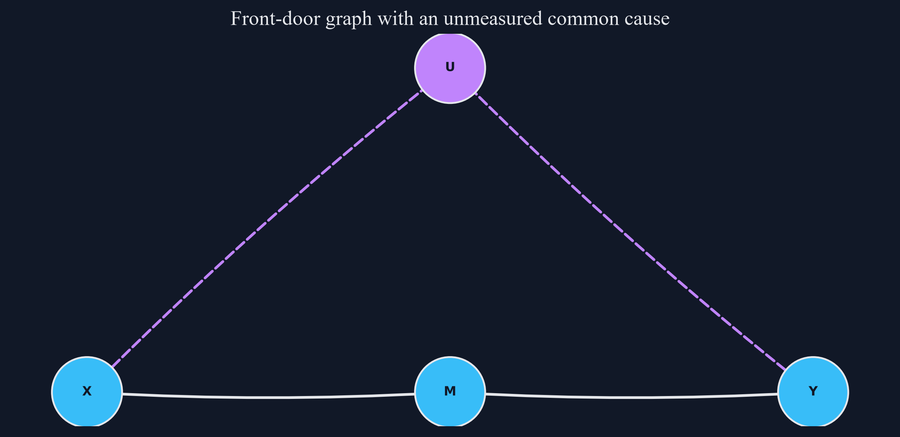

In [1]:
def contract_result(name, action, expected):
    expected_text = "Rejected" if expected in {"ValueError", "TypeError"} else expected
    try:
        action()
        return {"Check": name, "Expected result": expected_text, "Observed result": "Accepted", "Passed": False}
    except Exception as error:
        observed_text = "Rejected" if type(error).__name__ in {"ValueError", "TypeError"} else "Different rejection"
        return {"Check": name, "Expected result": expected_text, "Observed result": observed_text, "Passed": type(error).__name__ == expected}

frontdoor_graph = nx.DiGraph([("U", "X"), ("U", "Y"), ("X", "M"), ("M", "Y")])
positions = {"U": (1.5, 1.1), "X": (0, 0), "M": (1.5, 0), "Y": (3, 0)}
frontdoor_conditions = pd.DataFrame([
    {"Condition": "Mediator intercepts every directed treatment-outcome path", "Required": True, "Built into experiment": True},
    {"Condition": "No open back-door path from treatment to mediator", "Required": True, "Built into experiment": True},
    {"Condition": "Treatment blocks every mediator-outcome back-door path", "Required": True, "Built into experiment": True},
    {"Condition": "Unmeasured treatment-outcome common cause is allowed", "Required": False, "Built into experiment": True},
])
save_table(frontdoor_conditions, "frontdoor_conditions", "Conditions used by the front-door experiment.", "tab:chapter24-frontdoor-conditions")
display(frontdoor_conditions)

figure, axis = plt.subplots(figsize=(8.5, 4.2))
draw_graph(axis, frontdoor_graph, positions, "Front-door graph with an unmeasured common cause", latent={"U"})
figure.tight_layout()
save_figure(figure, "frontdoor_graph")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Comparing nonparametric identification with the linear calculation

Under the front-door conditions, the intervention distribution is expressed with observed treatment, mediator, and outcome distributions:

$$
p(y\mid\operatorname{do}(x))
=\sum_m p(m\mid x)\sum_{x'}p(y\mid m,x')p(x').
$$

Here, $x$ is the treatment value set by intervention, $m$ ranges over mediator values, $x'$ ranges over observed treatment values, $p(m\mid x)$ is the treatment-to-mediator relation, $p(y\mid m,x')$ is the outcome distribution within mediator-treatment groups, and $p(x')$ is the marginal treatment distribution.

In the linear full-mediation case used by the public library, the identified effect is the product of two fitted slopes:

$$
\widehat\beta_{\mathrm{FD}}=\widehat a\,\widehat b,
\qquad
M=\alpha_M+aX+e_M,
\qquad
Y=\alpha_Y+bM+cX+e_Y.
$$

Here, $\widehat\beta_{\mathrm{FD}}$ is the front-door estimate, $\widehat a$ is the fitted slope from mediator on treatment, $\widehat b$ is the mediator coefficient in the outcome equation that also includes treatment, $c$ is the fitted treatment coefficient used only as a warning about a direct path or remaining confounding, and the two $e$ terms are regression residuals.

The known data-generating system allows both treatment-outcome and mediator-outcome common causes as well as an optional direct path:

$$
X=c_UU+\varepsilon_X,\qquad
M=aX+c_VV+\varepsilon_M,\qquad
Y=bM+dX+g_UU+g_VV+\varepsilon_Y.
$$

Here, $U$ is the unmeasured treatment-outcome common cause, $V$ is the optional mediator-outcome common cause, $a$ and $b$ form the mediated effect, $d$ is a direct effect, $c_U$ and $g_U$ are the loadings of $U$, $c_V$ and $g_V$ are the loadings of $V$, and the three $\varepsilon$ terms are independent standard-normal shocks.

### Values used in the released front-door example

In [2]:
def simulate_frontdoor(n, a=1.0, b=1.0, direct=0.0, c_u=1.0, g_u=1.0, c_v=0.0, g_v=0.0, rng=None):
    generator = np.random.default_rng() if rng is None else rng
    common_xy = generator.standard_normal(n)
    common_my = generator.standard_normal(n)
    treatment_values = c_u * common_xy + generator.standard_normal(n)
    mediator_values = a * treatment_values + c_v * common_my + generator.standard_normal(n)
    outcome_values = b * mediator_values + direct * treatment_values + g_u * common_xy + g_v * common_my + generator.standard_normal(n)
    return treatment_values, mediator_values, outcome_values, common_xy, a * b + direct

frontdoor_parameters = pd.DataFrame([
    {"Parameter": "Observations in released example", "Symbol": "n", "Value": 6000},
    {"Parameter": "Treatment-to-mediator coefficient", "Symbol": "a", "Value": 0.7},
    {"Parameter": "Mediator-to-outcome coefficient", "Symbol": "b", "Value": 0.6},
    {"Parameter": "Known mediated effect", "Symbol": "a times b", "Value": 0.42},
    {"Parameter": "Treatment-outcome common-cause loading", "Symbol": "c U and g U", "Value": 1.0},
    {"Parameter": "Reported sensitivity strength", "Symbol": "lambda", "Value": 0.30},
])
demo_rng = np.random.default_rng(20260706)
demo_rows = []
for name, confounding in (("Clean", 0.0), ("Confounded", 1.0)):
    x, m, y, u, truth = simulate_frontdoor(6000, a=0.7, b=0.6, c_u=confounding, g_u=confounding, rng=demo_rng)
    result = frontdoor_analysis(x, m, y)
    low, high = result.sensitivity[0.30]
    demo_rows.append({"Panel": name, "Known effect": truth, "Front-door estimate": result.premium, "Ordinary estimate": result.ols_premium, "Wedge": result.wedge, "First slope": result.a_hat, "Second slope": result.b_hat, "Sensitivity low": low, "Sensitivity high": high})
frontdoor_demo = pd.DataFrame(demo_rows)
save_table(frontdoor_parameters, "frontdoor_structural_parameters", "Values used in the released front-door example.", "tab:chapter24-frontdoor-parameters")
frontdoor_demo_book = frontdoor_demo[["Panel", "Known effect", "Front-door estimate", "Ordinary estimate", "Sensitivity low", "Sensitivity high"]]
save_table(frontdoor_demo_book, "frontdoor_demo", "Front-door and ordinary estimates in clean and confounded panels.", "tab:chapter24-frontdoor-demo")
display(frontdoor_parameters)
display(frontdoor_demo);



,Parameter,Symbol,Value
0,Observations in released example,n,6000
1,Treatment-to-mediator coefficient,a,0.7
2,Mediator-to-outcome coefficient,b,0.6
3,Known mediated effect,a times b,0.42
4,Treatment-outcome common-cause loading,c U and g U,1
5,Reported sensitivity strength,lambda,0.3


,Panel,Known effect,Front-door estimate,Ordinary estimate,Wedge,First slope,Second slope,Sensitivity low,Sensitivity high
0,Clean,0.42,0.425817,0.432928,0.007111,0.70836,0.601131,0.272518,0.579116
1,Confounded,0.42,0.423957,0.909748,0.485792,0.700377,0.605327,0.273467,0.574447


### The front-door product bypasses treatment-outcome confounding

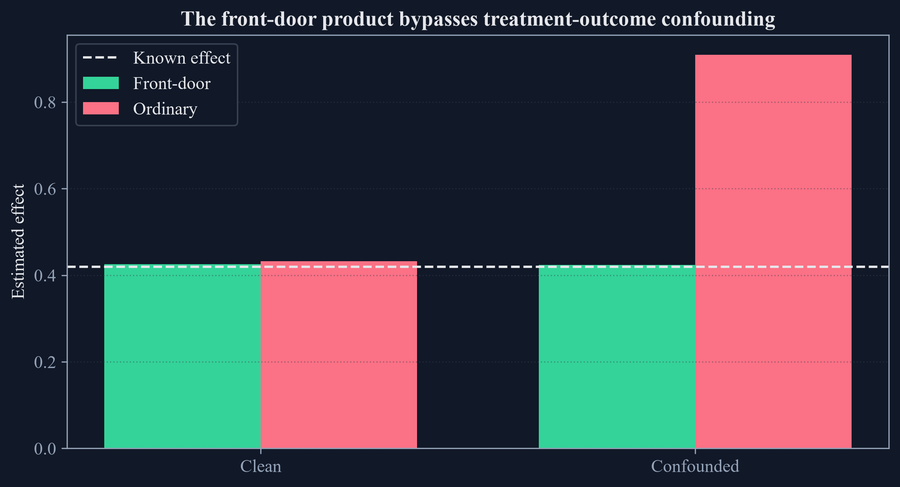

In [2]:
figure, axis = plt.subplots(figsize=(8.2, 4.5))
index = np.arange(len(frontdoor_demo))
axis.bar(index - 0.18, frontdoor_demo["Front-door estimate"], width=0.36, color=palette["green"], label="Front-door")
axis.bar(index + 0.18, frontdoor_demo["Ordinary estimate"], width=0.36, color=palette["rose"], label="Ordinary")
axis.axhline(0.42, color=palette["text"], linestyle="--", label="Known effect")
axis.set_xticks(index, frontdoor_demo["Panel"])
axis.set_ylabel("Estimated effect")
axis.set_title("The front-door product bypasses treatment-outcome confounding")
axis.legend()
axis.grid(axis="y", alpha=0.4)
figure.tight_layout()
save_figure(figure, "frontdoor_demo_comparison")

## Checking convergence across repeated samples

Repeated-sample error compares the front-door estimate with the ordinary estimate and with a back-door estimate that can use the common cause when it is observed:

$$
\operatorname{MSE}(\widehat\beta)=\frac{1}{R}\sum_{r=1}^{R}(\widehat\beta_r-\beta)^2.
$$

Here, $\operatorname{MSE}$ is mean squared error, $R$ is the number of repeated samples, $\widehat\beta_r$ is an effect estimate in repetition $r$, and $\beta$ is the known effect fixed by the generating equations.

### Repeated-sample recovery under an unmeasured treatment-outcome common cause

In [3]:
repetitions = 200
observations = 2000
recovery_rng = np.random.default_rng(102000001)
fd_values = np.empty(repetitions)
ordinary_values = np.empty(repetitions)
for repetition in range(repetitions):
    x, m, y, u, truth = simulate_frontdoor(observations, c_u=1.0, g_u=1.0, rng=recovery_rng)
    fd_values[repetition] = frontdoor_premium(x, m, y)
    ordinary_values[repetition] = ols_premium(x, y)
recovery_summary = pd.DataFrame([
    {"Method": "Front-door", "Mean estimate": fd_values.mean(), "Bias": fd_values.mean() - truth, "Mean squared error": mean_squared_error(fd_values, truth), "Repetitions": repetitions},
    {"Method": "Ordinary regression", "Mean estimate": ordinary_values.mean(), "Bias": ordinary_values.mean() - truth, "Mean squared error": mean_squared_error(ordinary_values, truth), "Repetitions": repetitions},
])
save_table(recovery_summary, "frontdoor_recovery_summary", "Repeated-sample recovery under an unmeasured treatment-outcome common cause.", "tab:chapter24-frontdoor-recovery")
display(recovery_summary);



,Method,Mean estimate,Bias,Mean squared error,Repetitions
0,Front-door,0.999912,-0.000088,0.001136,200
1,Ordinary regression,1.499999,0.499999,0.250748,200


### Front-door recovery across 200 generated samples

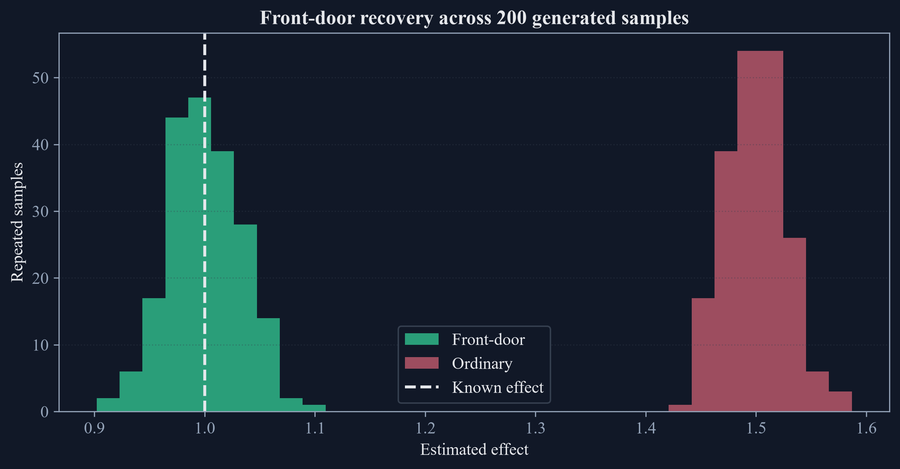

,Scenario,Mean estimate,Mean squared error,Repetitions
0,Front-door with measured common cause,0.996139,0.000947,200
1,Back-door with measured common cause,1.001877,0.000868,200
2,Front-door without confounding,0.99445,0.000988,200
3,Ordinary without confounding,0.995706,0.000916,200


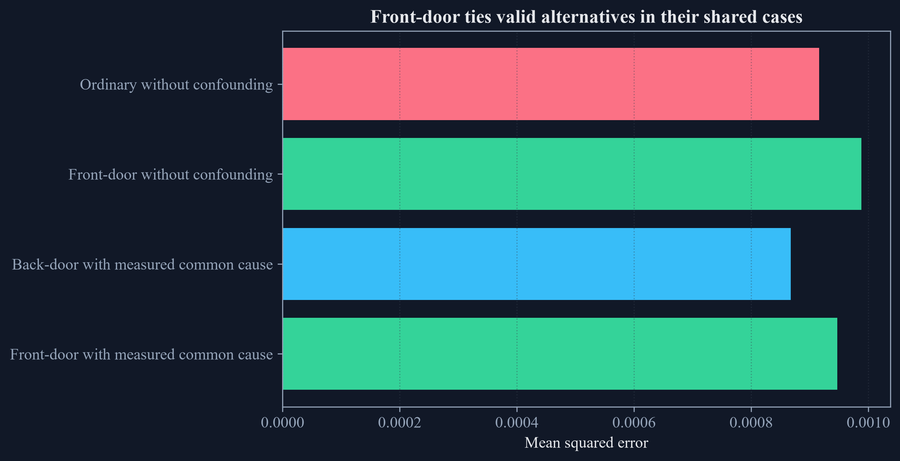

In [3]:
figure, axis = plt.subplots(figsize=(8.7, 4.6))
bins = np.linspace(min(fd_values.min(), ordinary_values.min()), max(fd_values.max(), ordinary_values.max()), 34)
axis.hist(fd_values, bins=bins, alpha=0.72, color=palette["green"], label="Front-door")
axis.hist(ordinary_values, bins=bins, alpha=0.60, color=palette["rose"], label="Ordinary")
axis.axvline(truth, color=palette["text"], linestyle="--", linewidth=2, label="Known effect")
axis.set_xlabel("Estimated effect")
axis.set_ylabel("Repeated samples")
axis.set_title("Front-door recovery across 200 generated samples")
axis.legend()
axis.grid(axis="y", alpha=0.35)
figure.tight_layout()
save_figure(figure, "frontdoor_estimate_distributions")

convergence_rng = np.random.default_rng(102000002)
scenario_values = {"Front-door with measured common cause": [], "Back-door with measured common cause": [], "Front-door without confounding": [], "Ordinary without confounding": []}
for repetition in range(repetitions):
    x, m, y, u, truth = simulate_frontdoor(observations, c_u=1.0, g_u=1.0, rng=convergence_rng)
    scenario_values["Front-door with measured common cause"].append(frontdoor_premium(x, m, y))
    scenario_values["Back-door with measured common cause"].append(ols_slope(y, x, u))
    x0, m0, y0, u0, truth0 = simulate_frontdoor(observations, c_u=0.0, g_u=0.0, rng=convergence_rng)
    scenario_values["Front-door without confounding"].append(frontdoor_premium(x0, m0, y0))
    scenario_values["Ordinary without confounding"].append(ols_premium(x0, y0))
convergence_table = pd.DataFrame([{"Scenario": name, "Mean estimate": np.mean(values), "Mean squared error": mean_squared_error(values, 1.0), "Repetitions": repetitions} for name, values in scenario_values.items()])
save_table(convergence_table, "frontdoor_convergence", "Convergence comparisons when the common cause is measured or absent.", "tab:chapter24-frontdoor-convergence")
display(convergence_table)

figure, axis = plt.subplots(figsize=(9.2, 4.8))
axis.barh(convergence_table["Scenario"], convergence_table["Mean squared error"], color=[palette["green"], palette["cyan"], palette["green"], palette["rose"]])
axis.set_xlabel("Mean squared error")
axis.set_title("Front-door ties valid alternatives in their shared cases")
axis.grid(axis="x", alpha=0.4)
figure.tight_layout()
save_figure(figure, "frontdoor_convergence_mse")

## Measuring the front-door wedge under sensitivity

The public library measures the gap between the front-door and ordinary estimates with an absolute wedge:

$$
W_{\mathrm{FD}}=\left|\widehat\beta_{\mathrm{FD}}-\widehat\beta_{\mathrm{OLS}}\right|.
$$

Here, $W_{\mathrm{FD}}$ is the diagnostic wedge, $\widehat\beta_{\mathrm{FD}}$ is the front-door product, and $\widehat\beta_{\mathrm{OLS}}$ is the ordinary treatment slope. A large wedge records disagreement under the stated design; it does not prove which assumption failed in an unknown graph.

,Common-cause loading,Mean wedge,Wedge standard deviation,Repetitions
0,0,0.023861,0.018981,200
1,1,0.498546,0.035186,200
2,1.5,0.691442,0.035212,200


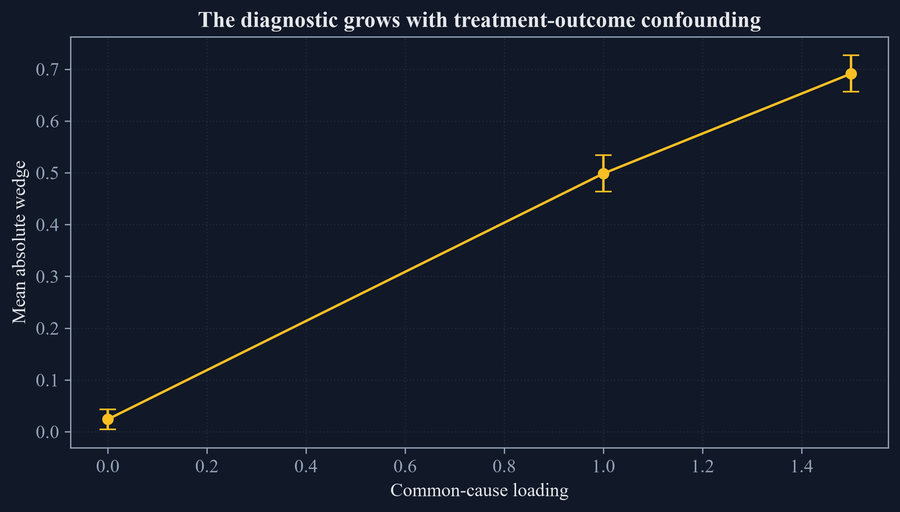

In [4]:
wedge_rng = np.random.default_rng(102000004)
wedge_rows = []
for confounding in (0.0, 1.0, 1.5):
    values = []
    for repetition in range(repetitions):
        x, m, y, u, truth = simulate_frontdoor(observations, c_u=confounding, g_u=confounding, rng=wedge_rng)
        values.append(frontdoor_ols_wedge(x, m, y))
    wedge_rows.append({"Common-cause loading": confounding, "Mean wedge": np.mean(values), "Wedge standard deviation": np.std(values, ddof=1), "Repetitions": repetitions})
wedge_sweep = pd.DataFrame(wedge_rows)
save_table(wedge_sweep, "frontdoor_wedge_sweep", "Front-door and ordinary-estimate disagreement as confounding increases.", "tab:chapter24-frontdoor-wedge")
display(wedge_sweep)

figure, axis = plt.subplots(figsize=(7.8, 4.5))
axis.errorbar(wedge_sweep["Common-cause loading"], wedge_sweep["Mean wedge"], yerr=wedge_sweep["Wedge standard deviation"], marker="o", capsize=5, color=palette["amber"])
axis.set_xlabel("Common-cause loading")
axis.set_ylabel("Mean absolute wedge")
axis.set_title("The diagnostic grows with treatment-outcome confounding")
axis.grid(alpha=0.4)
figure.tight_layout()
save_figure(figure, "frontdoor_wedge_sweep")

The library's linear sensitivity interval expands the second-stage coefficient by a declared mediator-outcome confounding strength:

$$
\mathcal I_{\lambda}
=\left[
\widehat a\left(\widehat b-\lambda|\widehat a|-\lambda s_b\right),
\widehat a\left(\widehat b+\lambda|\widehat a|+\lambda s_b\right)
\right].
$$

Here, $\mathcal I_{\lambda}$ is the reported interval, $\lambda\geq0$ is the assumed sensitivity strength, $\widehat a$ is the first-stage mediator slope, $\widehat b$ is the second-stage mediator coefficient, and $s_b$ is the standard error of $\widehat b$. The interval is a warning calculation under this rule, not a test that proves the mediator is protected.

### Coverage of the known effect under mediator-outcome confounding

In [5]:
sensitivity_grid = (0.0, 0.15, 0.30, 0.45, 0.60)
sensitivity_rng = np.random.default_rng(102000003)
coverage = {value: 0 for value in sensitivity_grid}
for repetition in range(repetitions):
    x, m, y, u, truth = simulate_frontdoor(observations, c_u=1.0, g_u=1.0, c_v=0.8, g_v=0.8, rng=sensitivity_rng)
    for value in sensitivity_grid:
        low, high = frontdoor_sensitivity_interval(x, m, y, value)
        coverage[value] += int(low <= truth <= high)
sensitivity_coverage = pd.DataFrame([{"Sensitivity strength": value, "Coverage": coverage[value] / repetitions, "Repetitions": repetitions} for value in sensitivity_grid])
save_table(sensitivity_coverage, "frontdoor_sensitivity_coverage", "Coverage of the known effect under mediator-outcome confounding.", "tab:chapter24-frontdoor-sensitivity-coverage")
display(sensitivity_coverage);



,Sensitivity strength,Coverage,Repetitions
0,0,0,200
1,0.15,0,200
2,0.3,0,200
3,0.45,1,200
4,0.6,1,200


### The warning band must widen before it covers the truth

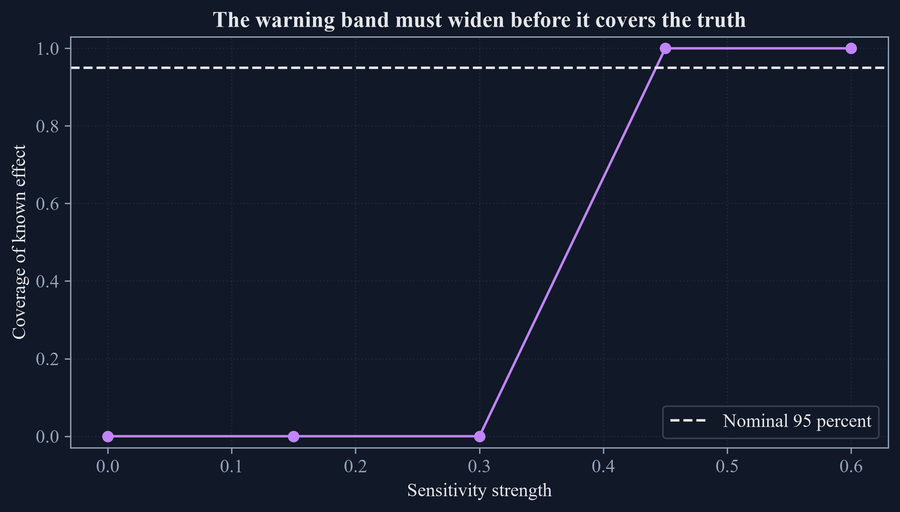

,Sensitivity strength,Lower end,Upper end,Width,Contains known effect
0,0,0.984526,0.984526,0,False
1,0.15,0.834184,1.134867,0.300684,True
2,0.3,0.683842,1.285209,0.601367,True
3,0.45,0.5335,1.435551,0.902051,True
4,0.6,0.383158,1.585893,1.202734,True


In [5]:
figure, axis = plt.subplots(figsize=(7.8, 4.5))
axis.plot(sensitivity_coverage["Sensitivity strength"], sensitivity_coverage["Coverage"], marker="o", color=palette["violet"])
axis.axhline(0.95, color=palette["text"], linestyle="--", label="Nominal 95 percent")
axis.set_ylim(-0.03, 1.03)
axis.set_xlabel("Sensitivity strength")
axis.set_ylabel("Coverage of known effect")
axis.set_title("The warning band must widen before it covers the truth")
axis.legend()
axis.grid(alpha=0.4)
figure.tight_layout()
save_figure(figure, "frontdoor_sensitivity_coverage")

interval_rng = np.random.default_rng(240202)
x, m, y, u, truth = simulate_frontdoor(40000, c_u=1.0, g_u=1.0, rng=interval_rng)
interval_rows = []
for value in sensitivity_grid:
    low, high = frontdoor_sensitivity_interval(x, m, y, value)
    interval_rows.append({"Sensitivity strength": value, "Lower end": low, "Upper end": high, "Width": high - low, "Contains known effect": low <= truth <= high})
sensitivity_intervals = pd.DataFrame(interval_rows)
save_table(sensitivity_intervals, "frontdoor_sensitivity_intervals", "Sensitivity intervals for one known full-mediation sample.", "tab:chapter24-frontdoor-sensitivity-intervals")
display(sensitivity_intervals);



### Sensitivity intervals widen monotonically

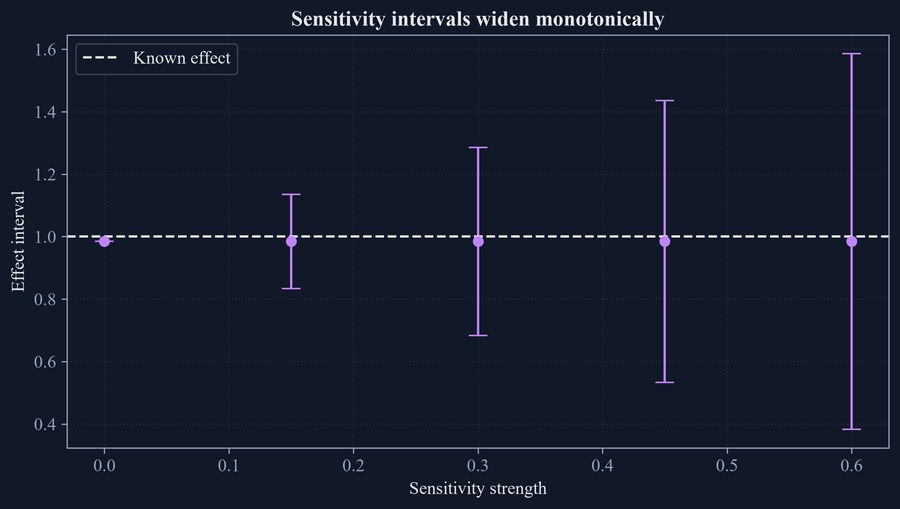

In [5]:
figure, axis = plt.subplots(figsize=(8.2, 4.7))
centers = (sensitivity_intervals["Lower end"] + sensitivity_intervals["Upper end"]) / 2
errors = (sensitivity_intervals["Upper end"] - sensitivity_intervals["Lower end"]) / 2
axis.errorbar(sensitivity_intervals["Sensitivity strength"], centers, yerr=errors, fmt="o", capsize=6, color=palette["violet"])
axis.axhline(truth, color=palette["text"], linestyle="--", label="Known effect")
axis.set_xlabel("Sensitivity strength")
axis.set_ylabel("Effect interval")
axis.set_title("Sensitivity intervals widen monotonically")
axis.legend()
axis.grid(alpha=0.4)
figure.tight_layout()
save_figure(figure, "frontdoor_sensitivity_intervals")

## Full-Mediation Warning

The direct-path warning divides the fitted treatment coefficient in the outcome equation by its standard error:

$$
T_{\mathrm{direct}}=\frac{\widehat c}{\operatorname{SE}(\widehat c)}.
$$

Here, $T_{\mathrm{direct}}$ is the warning statistic, $\widehat c$ is the treatment coefficient in the regression of outcome on mediator and treatment, and $\operatorname{SE}(\widehat c)$ is its standard error. Under an unmeasured treatment-outcome common cause, this statistic can fire even when the true direct effect is zero.

### Direct-path warning in two cases that both trigger it

,Case,True direct effect,Fitted direct coefficient,Standard error,Absolute t statistic,Warning fired
0,True direct path,0.6,1.105869,0.010607,104.255632,True
1,Full mediation with treatment-outcome confounding,0,0.48809,0.010617,45.97191,True


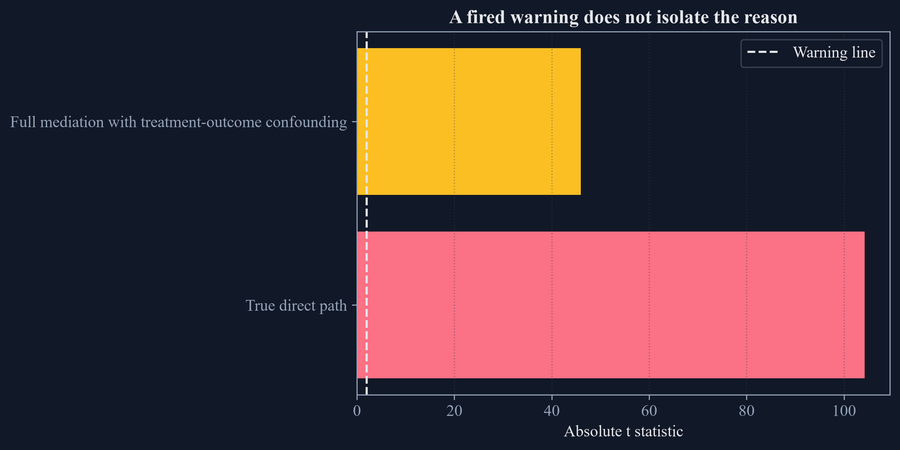

In [6]:
direct_rng = np.random.default_rng(3)
direct_rows = []
for name, direct in (("True direct path", 0.6), ("Full mediation with treatment-outcome confounding", 0.0)):
    x, m, y, u, truth = simulate_frontdoor(20000, direct=direct, c_u=1.0, g_u=1.0, rng=direct_rng)
    warning = direct_path_test(x, m, y)
    direct_rows.append({"Case": name, "True direct effect": direct, "Fitted direct coefficient": warning.coef, "Standard error": warning.se, "Absolute t statistic": abs(warning.tstat), "Warning fired": warning.fired})
direct_path_caveat = pd.DataFrame(direct_rows)
direct_path_book = direct_path_caveat[["Case", "Fitted direct coefficient", "Absolute t statistic", "Warning fired"]]
save_table(direct_path_book, "frontdoor_direct_path_caveat", "Direct-path warning in two cases that both trigger it.", "tab:chapter24-frontdoor-direct-path")
display(direct_path_caveat)

figure, axis = plt.subplots(figsize=(9, 4.6))
axis.barh(direct_path_caveat["Case"], direct_path_caveat["Absolute t statistic"], color=[palette["rose"], palette["amber"]])
axis.axvline(2, color=palette["text"], linestyle="--", label="Warning line")
axis.set_xlabel("Absolute t statistic")
axis.set_title("A fired warning does not isolate the reason")
axis.legend()
axis.grid(axis="x", alpha=0.4)
figure.tight_layout()
save_figure(figure, "frontdoor_direct_path_caveat");



### Known-value and input checks for the released front-door calculations

In [6]:
checks = []
large_rng = np.random.default_rng(1)
x, m, y, u, truth = simulate_frontdoor(60000, a=1.2, b=0.7, c_u=1.0, g_u=1.0, rng=large_rng)
known_beta = frontdoor_premium(x, m, y)
bundle = frontdoor_analysis(x, m, y)
checks.extend([
    {"Check": "Known-effect recovery", "Observed": known_beta, "Expected": truth, "Passed": abs(known_beta - truth) < 0.03},
    {"Check": "Bundle product identity", "Observed": bundle.premium, "Expected": bundle.a_hat * bundle.b_hat, "Passed": np.isclose(bundle.premium, bundle.a_hat * bundle.b_hat)},
    {"Check": "Zero-sensitivity collapse", "Observed": bundle.sensitivity[0.0][1] - bundle.sensitivity[0.0][0], "Expected": 0.0, "Passed": np.isclose(bundle.sensitivity[0.0][1], bundle.sensitivity[0.0][0])},
])
contract_checks = pd.DataFrame(checks + [
    contract_result("Unequal lengths", lambda: frontdoor_premium(np.zeros(9), np.zeros(10), np.zeros(10)), "ValueError"),
    contract_result("Too few observations", lambda: frontdoor_premium(np.zeros(2), np.zeros(2), np.zeros(2)), "ValueError"),
    contract_result("Negative sensitivity strength", lambda: frontdoor_sensitivity_interval(np.zeros(10), np.zeros(10), np.zeros(10), -0.1), "ValueError"),
    contract_result("Two-dimensional treatment", lambda: frontdoor_premium(np.zeros((10, 2)), np.zeros(10), np.zeros(10)), "ValueError"),
])
frontdoor_summary = pd.DataFrame([
    {"Question": "Can an unmeasured treatment-outcome common cause remain?", "Answer": "Yes, under the front-door conditions"},
    {"Question": "Must the mediator carry the whole treatment effect?", "Answer": "Yes"},
    {"Question": "Can mediator-outcome confounding be ignored?", "Answer": "No"},
    {"Question": "Does the sensitivity interval prove the assumptions?", "Answer": "No"},
    {"Question": "Does a fired direct-path warning identify one cause?", "Answer": "No"},
])
save_table(contract_checks, "frontdoor_contract_checks", "Known-value and input checks for the released front-door calculations.", "tab:chapter24-frontdoor-contract-checks")
save_table(frontdoor_summary, "frontdoor_section_summary", "Main conclusions from the front-door experiments.", "tab:chapter24-frontdoor-summary")
display(contract_checks)
display(frontdoor_summary)

,Check,Observed,Expected,Passed,Expected result,Observed result
0,Known-effect recovery,0.833963,0.84,True,NaN,NaN
1,Bundle product identity,0.833963,0.833963,True,NaN,NaN
2,Zero-sensitivity collapse,0,0,True,NaN,NaN
3,Unequal lengths,NaN,NaN,True,Rejected,Rejected
4,Too few observations,NaN,NaN,True,Rejected,Rejected
5,Negative sensitivity strength,NaN,NaN,True,Rejected,Rejected
6,Two-dimensional treatment,NaN,NaN,True,Rejected,Rejected


,Question,Answer
0,Can an unmeasured treatment-outcome common cau...,"Yes, under the front-door conditions"
1,Must the mediator carry the whole treatment ef...,Yes
2,Can mediator-outcome confounding be ignored?,No
3,Does the sensitivity interval prove the assump...,No
4,Does a fired direct-path warning identify one ...,No


## Tests

In [7]:
assert recovery_summary.loc[recovery_summary["Method"] == "Front-door", "Mean squared error"].iloc[0] <= 0.02
assert recovery_summary.loc[recovery_summary["Method"] == "Ordinary regression", "Mean squared error"].iloc[0] >= 0.15
assert abs(fd_values.mean() - 1.0) < 0.05
assert convergence_table["Mean squared error"].max() <= 0.02
assert list(wedge_sweep["Mean wedge"]) == sorted(wedge_sweep["Mean wedge"])
assert sensitivity_coverage.loc[sensitivity_coverage["Sensitivity strength"] == 0.45, "Coverage"].iloc[0] >= 0.80
assert sensitivity_coverage.loc[sensitivity_coverage["Sensitivity strength"] == 0.60, "Coverage"].iloc[0] >= 0.90
assert np.all(np.diff(sensitivity_intervals["Width"]) >= -1e-12)
assert direct_path_caveat["Warning fired"].all()
assert contract_checks["Passed"].all()
for stem in ["frontdoor_graph", "frontdoor_demo_comparison", "frontdoor_estimate_distributions", "frontdoor_convergence_mse", "frontdoor_wedge_sweep", "frontdoor_sensitivity_coverage", "frontdoor_sensitivity_intervals", "frontdoor_direct_path_caveat"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["frontdoor_conditions", "frontdoor_structural_parameters", "frontdoor_demo", "frontdoor_recovery_summary", "frontdoor_convergence", "frontdoor_wedge_sweep", "frontdoor_sensitivity_coverage", "frontdoor_sensitivity_intervals", "frontdoor_direct_path_caveat", "frontdoor_contract_checks", "frontdoor_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()